In [1]:
import os
import sys
from pathlib import Path

import joblib
import pandas as pd

# Run from project root so relative paths (data/raw, models/) and `app` imports work
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))

from app.data import load_data, split_xy
from app.features import build_features
from app.metrics import threshold_metrics
from app.models import make_xgb

In [2]:
splits = split_xy(build_features(load_data()))

X_train, y_train = splits["train"]
X_val, y_val = splits["val"]
X_test, y_test = splits["test"]

print(f"train: {X_train.shape}, val: {X_val.shape}, test: {X_test.shape}")

train: (1142581, 10), val: (154094, 10), test: (555719, 10)


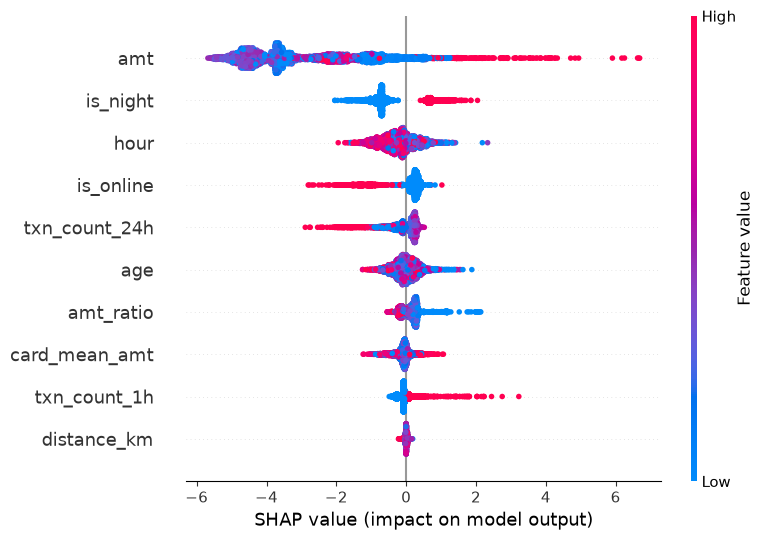

In [3]:
import matplotlib.pyplot as plt
import shap

final_model = joblib.load("models/model.joblib")

# 5,000 random test rows are enough for a stable global picture and fast to compute
X_sample = X_test.sample(5000, random_state=42)

explainer = shap.TreeExplainer(final_model)
sv = explainer(X_sample)

shap.plots.beeswarm(sv, show=False)
plt.tight_layout()
Path("reports").mkdir(exist_ok=True)
plt.savefig("reports/shap_summary.png", dpi=150)
plt.show()

**Conclusion:** The model's top drivers match the EDA: transaction amount dominates
(large amounts push strongly towards fraud), followed by night-time and hour. A burst of
transactions within the last hour raises risk, while many transactions over 24h lowers it —
an active customer looks different from a sudden burst.

Two results need care. `is_online` pushes towards *legitimate* once amount and time are
known, despite online categories having the highest raw fraud rates in EDA: SHAP shows the
model's conditional reasoning, not causal effects. `amt`, `amt_ratio` and `card_mean_amt`
are correlated, so SHAP splits credit between them unpredictably — their individual
attributions should not be over-interpreted. `distance_km` contributes almost nothing
(merchant locations are random in this synthetic data) — a candidate to drop.